<a href="https://colab.research.google.com/github/sen-soumya/Optical-communication/blob/main/Adaptive_Optical_link_pre_distortion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import random
from collections import deque
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
print("Libraries successfully imported and random seeds initialized.")

Libraries successfully imported and random seeds initialized.


### 1. Optical Channel Environment


In [2]:
class ParametricOpticalLinkEnv:
    def __init__(self, fiber_length_km=0.5, beta2_disp=20e-3, gamma_nl=1.5, alpha_chirp=4.0):
        """
        Parameters:
          fiber_length_km : Physical link length (L)
          beta2_disp      : Dispersion parameter (ps^2/km)
          gamma_nl        : Non-linear Kerr coefficient (1/W/km)
          alpha_chirp     : Laser linewidth enhancement factor
        """
        self.L = fiber_length_km
        self.beta2 = beta2_disp
        self.gamma = gamma_nl
        self.alpha = alpha_chirp

        self.state_dim = 4  # [Last Received, Prev Received, Temperature, Total Dispersion]
        self.reset()

    def reset(self):
        self.history = [0.0, 0.0]
        self.temperature = 300.0
        return np.array([
            self.history[0],
            self.history[1],
            self.temperature,
            self.L * self.beta2
        ], dtype=np.float32)

    def step(self, action, target_bit):
        # Base voltage determined by target transmission bit
        base_voltage = 1.6 if target_bit == 1 else 0.05
        input_voltage = np.clip(base_voltage + action, 0.0, 2.5)

        # 1. Simulate Transient Laser Wavelength Chirp
        current_slope = (input_voltage - (1.0 if self.history[0] > 0.4 else 0.1))
        chirp_penalty = self.alpha * current_slope * 0.1

        # 2. Simulate Parametric Chromatic Dispersion (pulse broadening over distance)
        dispersion_bleed = 0.25 * (self.beta2 * self.L) * self.history[0] + 0.12 * (self.beta2 * self.L) * self.history[1]

        # 3. Combine raw optical intensity
        raw_optical_intensity = 0.8 * input_voltage + dispersion_bleed - chirp_penalty

        # 4. Self-Phase Modulation (SPM) Non-linear saturation
        received_power = np.tanh(raw_optical_intensity * (1.0 - 0.08 * self.gamma * (raw_optical_intensity ** 2)))
        received_power = np.clip(received_power, 0.0, 1.0)

        # Update rolling metrics
        self.history.insert(0, received_power)
        self.history.pop()
        self.temperature += 0.4 * (input_voltage ** 2) - 0.1 * (self.temperature - 300.0)

        # Compute reward components (Tracking error + Power conservation)
        target_power = 0.85 if target_bit == 1 else 0.02
        signal_error = (received_power - target_power) ** 2
        energy_penalty = 0.25 * (input_voltage ** 2)
        reward = -(signal_error + energy_penalty)

        next_state = np.array([
            self.history[0],
            self.history[1],
            self.temperature,
            self.L * self.beta2
        ], dtype=np.float32)

        return next_state, reward

### 2. Deep Q-Network


In [3]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim)
        )

    def forward(self, x):
        return self.fc(x)

class DQNAgent:
    def __init__(self, state_dim):
        # Action space: offsets added to base laser voltages
        self.action_space = np.linspace(-0.6, 0.6, 11)
        self.memory = deque(maxlen=2000)
        self.gamma = 0.95
        self.epsilon = 1.0
        self.epsilon_decay = 0.99
        self.epsilon_min = 0.01

        self.model = QNetwork(state_dim, len(self.action_space))
        self.optimizer = optim.Adam(self.model.parameters(), lr=0.002)

    def select_action(self, state):
        if random.random() < self.epsilon:
            return random.randint(0, len(self.action_space) - 1)

        state_t = torch.FloatTensor(state).unsqueeze(0)
        with torch.no_grad():
            return torch.argmax(self.model(state_t)).item()

    def train(self, batch_size=32):
        if len(self.memory) < batch_size:
            return

        batch = random.sample(self.memory, batch_size)
        states, actions, rewards, next_states = zip(*batch)

        states = torch.FloatTensor(np.array(states))
        actions = torch.LongTensor(actions).unsqueeze(1)
        rewards = torch.FloatTensor(rewards)
        next_states = torch.FloatTensor(np.array(next_states))

        # Compute Q Targets
        current_q = self.model(states).gather(1, actions).squeeze()
        next_q = self.model(next_states).max(1)[0].detach()
        target_q = rewards + self.gamma * next_q

        # Perform gradient step
        loss = nn.MSELoss()(current_q, target_q)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        # Decay exploration rate
        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay

### 3. Simulation & Multi-Scenario Evaluation


In [4]:
def run_link_simulation(env_instance, total_bits=600):
    agent = DQNAgent(env_instance.state_dim)
    bit_stream = [random.choice([0, 1]) for _ in range(total_bits)]
    state = env_instance.reset()
    reward_history = []

    for target_bit in bit_stream:
        action_idx = agent.select_action(state)
        action_val = agent.action_space[action_idx]

        next_state, reward = env_instance.step(action_val, target_bit)
        agent.memory.append((state, action_idx, reward, next_state))
        agent.train()
        state = next_state
        reward_history.append(reward)

    return reward_history

 Running training simulation for Short Link (0.2 km) - Low Blur with Beta2=22.0 and Gamma=1.2...
 Running training simulation for Long Link (2.0 km) - High Distortion with Beta2=22.0 and Gamma=1.2...


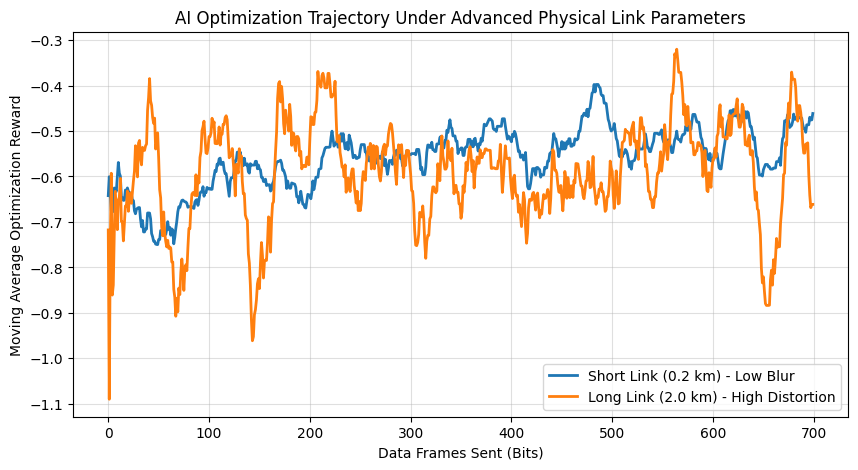

In [6]:
# Initialize physical scenarios
scenarios = {
    "Short Link (0.2 km) - Low Blur": ParametricOpticalLinkEnv(fiber_length_km=0.2, beta2_disp=22.0, gamma_nl=1.2),
    "Long Link (2.0 km) - High Distortion": ParametricOpticalLinkEnv(fiber_length_km=2.0, beta2_disp=22.0, gamma_nl=1.2)
}

results = {}

for name, env in scenarios.items():
    print(f" Running training simulation for {name} with Beta2={env.beta2} and Gamma={env.gamma}...")
    results[name] = run_link_simulation(env, total_bits=700)

# Plot moving averages of the trajectories
plt.figure(figsize=(10, 5))
for name, history in results.items():
    smoothed = [np.mean(history[max(0, i-25):i+1]) for i in range(len(history))]
    plt.plot(smoothed, label=name, lw=2)

plt.title("AI Optimization Trajectory Under Advanced Physical Link Parameters")
plt.xlabel("Data Frames Sent (Bits)")
plt.ylabel("Moving Average Optimization Reward")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()